<a href="https://colab.research.google.com/github/202422/AI-Powered-Academic-Recovery-Dashboard/blob/main/Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Packages Import and Data loading**

In [47]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import shap
import matplotlib.pyplot as plt

In [4]:
pd.set_option("display.max_columns", None)

In [5]:
df = pd.read_csv("/content/df_transformed.csv")
df

,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,FinalGrade
0,0,18,1,0,0,4,4,0,4,0,1,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,6,6
1,0,17,1,0,1,1,1,0,2,0,0,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,4,6
2,0,15,1,1,1,1,1,0,2,2,1,1,2,3,1,0,1,0,1,1,1,0,4,3,2,2,3,3,10,10
3,0,15,1,0,1,4,2,1,3,1,1,1,3,0,0,1,1,1,1,1,1,1,3,2,2,1,1,5,2,15
4,0,16,1,0,1,3,3,2,2,1,0,1,2,0,0,1,1,0,1,1,0,0,4,3,2,1,2,5,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,1,20,1,1,0,2,2,3,3,0,2,1,2,2,0,1,1,0,1,1,0,0,5,5,4,4,5,4,11,9
353,1,17,1,1,1,3,1,3,3,0,1,2,1,0,0,0,0,0,0,1,1,0,2,4,5,3,4,2,3,16
354,1,21,0,0,1,1,1,2,2,0,2,1,1,3,0,0,0,0,0,1,0,0,5,5,3,3,3,3,3,7
355,1,18,0,1,1,3,2,3,2,0,1,3,1,0,0,0,0,0,0,1,1,0,4,4,1,3,4,5,0,10


# **Modelling**

In [23]:
param_grid = {
    'n_estimators': [300, 500, 700],
    'learning_rate': [0.001, 0.01, 0.05],
    'max_depth': [2, 3, 5],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [0.8, 0.9, 1]
}

In [17]:
# Separate features (X) and target (y)
X = df.drop('FinalGrade', axis=1)
y = df['FinalGrade']

In [24]:
# Initialize XGBRegressor
xgb = XGBRegressor(random_state=42)

In [25]:
# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='neg_mean_squared_error', # Using negative MSE for regression, GridSearchCV maximizes this
    cv=5, # 5-fold cross-validation
    n_jobs=-1, # Use all available CPU cores
    verbose=1 # Display progress
)

In [26]:
# Fit GridSearchCV to the data
grid_search.fit(X, y)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None...
                                    max_depth=None, max_leaves=None,
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 0.9, 1],
                         'learning_rate': [0.001, 0.01, 0.05],
                         'max_depth': [2, 3, 5],
                         'n_estimators': [300, 500, 700],
                         'subsample': [0.6, 0.7, 0.8]},
             scoring='neg_mean_squared_error', verbose=1)

In [27]:
# Display the best parameters and best score
print("Best parameters found: ", grid_search.best_params_)
print("Best RMSE found: ", (-grid_search.best_score_)**0.5) # Convert negative MSE to RMSE

Best parameters found:  {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 700, 'subsample': 0.7}
Best RMSE found:  2.957200369792282


In [22]:
y.std()

3.227796940207426

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
xgb_final = XGBRegressor(**grid_search.best_params_)
xgb_final

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.01, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=700,
             n_jobs=None, num_parallel_tree=None, ...)

In [42]:
xgb_final.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.01, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=700,
             n_jobs=None, num_parallel_tree=None, ...)

In [44]:
# Make predictions on the test set
y_pred = xgb_final.predict(X_test)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate R2 score
r2 = r2_score(y_test, y_pred)

print(f"XGBoost Model RMSE on Test Set: {rmse:.4f}")
print(f"XGBoost Model R2 Score on Test Set: {r2:.4f}")

XGBoost Model RMSE on Test Set: 2.7056
XGBoost Model R2 Score on Test Set: 0.2401


In [46]:
feature_importances = xgb_final.feature_importances_
feature_names = X.columns

# Create a pandas Series for better visualization
importance_df = pd.Series(feature_importances, index=feature_names)

# Sort the features by importance in descending order
sorted_importance = importance_df.sort_values(ascending=False)

print("Most important features in xgb_final:")
sorted_importance

Most important features in xgb_final:


,0
failures,0.067474
schoolsup,0.057011
internet,0.047883
absences,0.046278
studytime,0.044498
Walc,0.043222
sex,0.042998
health,0.038499
Fjob,0.038076
reason,0.036633


## **Most influential features**


| Feature       | Importance | Interpretation                                                                            |
| ------------- | ---------- | ----------------------------------------------------------------------------------------- |
| **failures**  | **0.067**  | Previous academic failures are the strongest predictor of performance.                    |
| **schoolsup** | 0.057      | Students receiving school support perform differently (often weaker students receive it). |
| **internet**  | 0.048      | Access to internet significantly affects academic results.                                |
| **absences**  | 0.046      | More absences → lower performance.                                                        |
| **studytime** | 0.044      | More study time improves grades.                                                          |
| **Walc**      | 0.043      | Weekend alcohol consumption negatively impacts performance.                               |
| **sex**       | 0.043      | Gender shows measurable differences in outcomes.                                          |
| **health**    | 0.038      | Health condition influences learning ability.                                             |



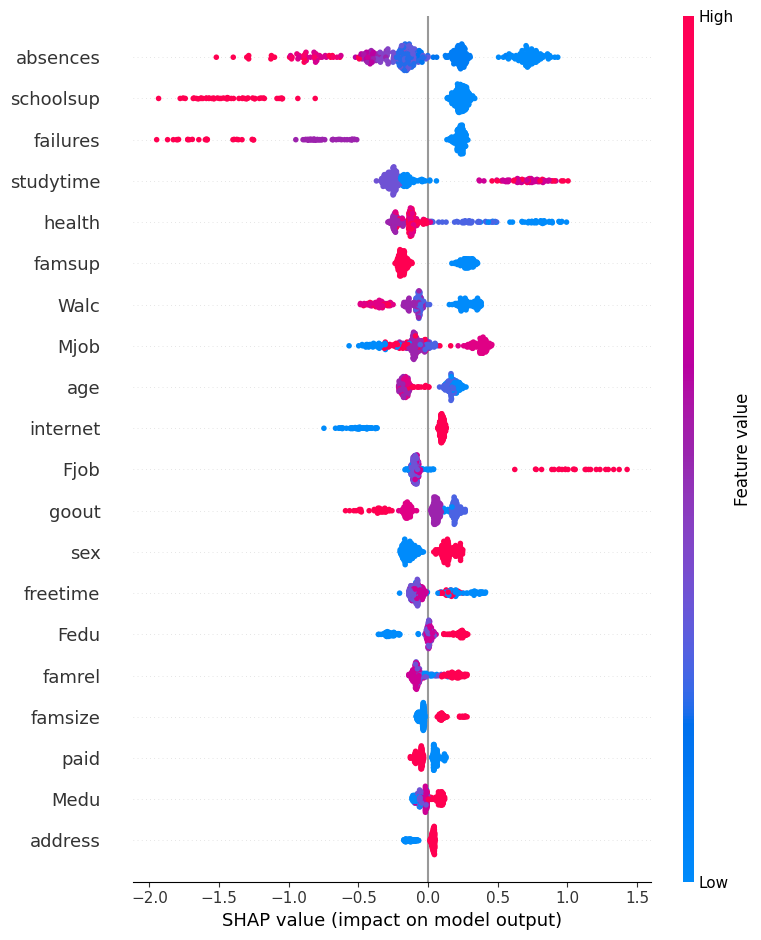

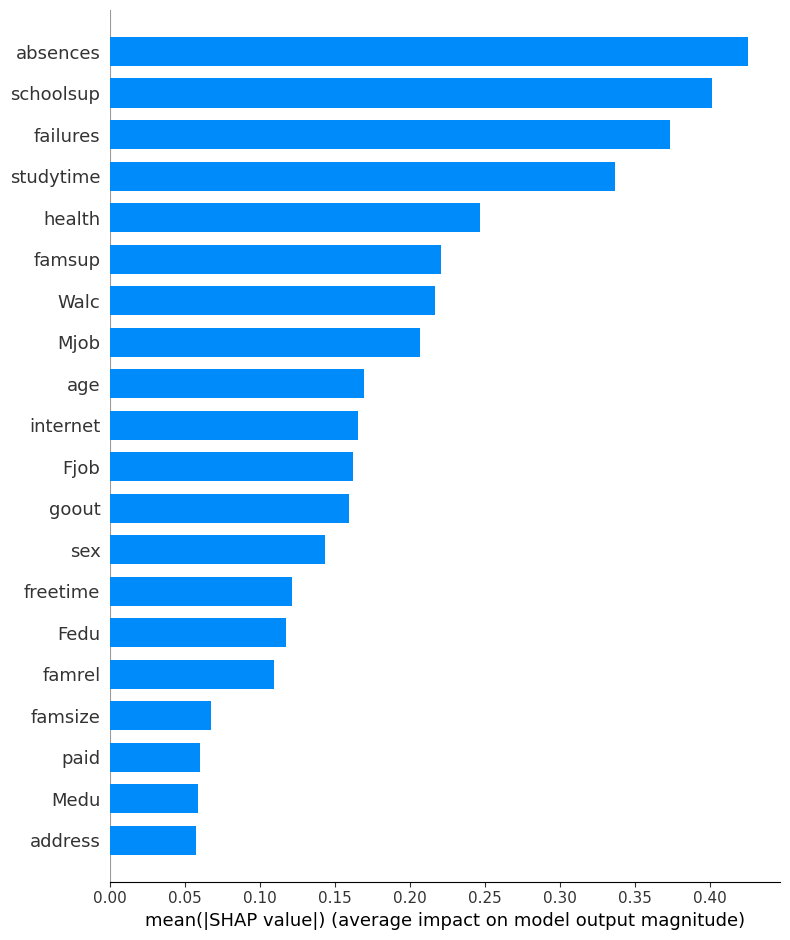

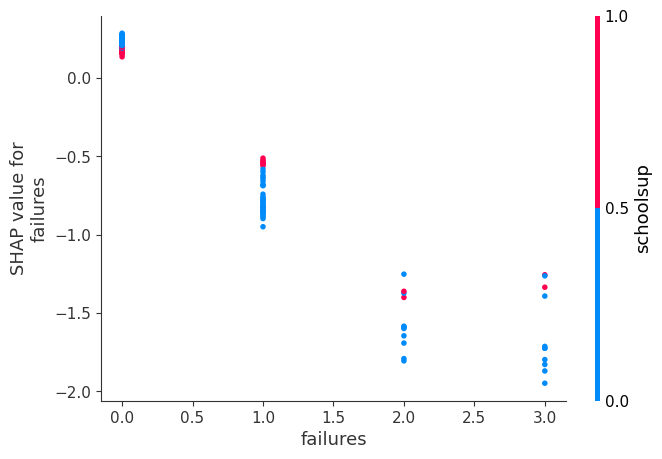

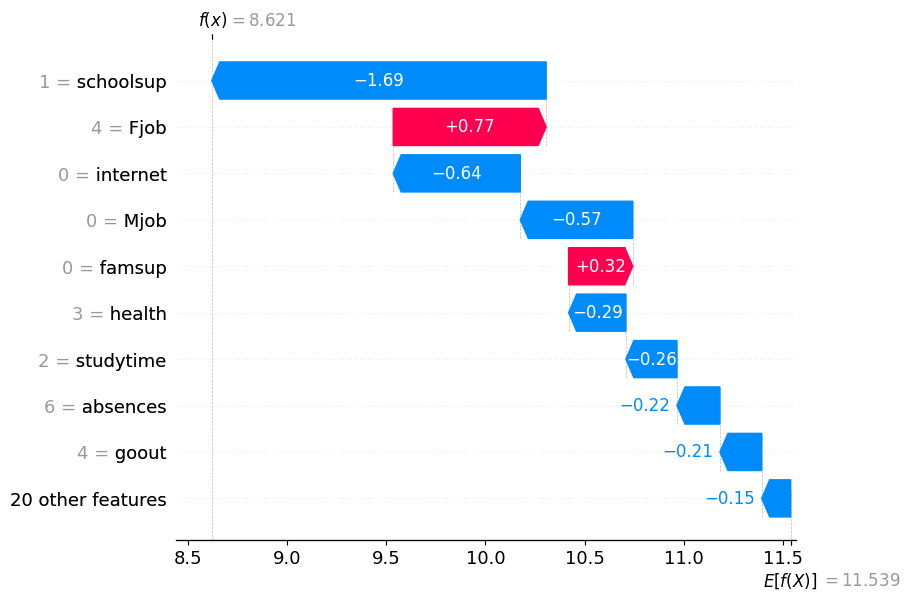

In [48]:
explainer = shap.Explainer(xgb_final)
shap_values = explainer(X)

# Global importance
shap.summary_plot(shap_values, X)

# Clean bar plot
shap.summary_plot(shap_values, X, plot_type="bar")

# Feature behavior
shap.dependence_plot("failures", shap_values.values, X)

# Individual explanation
shap.plots.waterfall(shap_values[0])


## **Key interpretations — top features and patterns:**

1. **absences** (top-ranked)  
   - Very strong negative effect when high (red dots far left, down to -2).  
   - Low absences (blue) mildly positive or near zero.  
   → **High number of absences is one of the most damaging factors** — pulls predicted grade down sharply and consistently.

2. **schoolsup** (extra school support/tutoring — yes/no)  
   - When present (likely red/high = yes), strong positive push (many red dots to the right, up to ~1.5).  
   - When absent (blue), tends to be neutral or slightly negative.  
   → **Receiving school support is one of the most powerful positive interventions** in this model — much more impactful than simple correlations suggested.

3. **failures** (past class failures)  
   - High failures (red) strongly negative (dots pulled far left).  
   - Zero failures (blue cluster) mostly near zero or slightly positive.  
   → Classic strong negative driver — previous failures heavily penalize the predicted grade.

4. **studytime**  
   - High study time (red) consistently pushes predictions **up** (right side, many positive SHAP values).  
   - Low study time (blue) pulls down mildly to moderately.  
   → Clear **positive** and fairly linear effect — more weekly study hours reliably improve predicted performance.

5. **health**  
   - Very good health (likely red/high) → tends to positive SHAP (right).  
   - Poor health (blue/low) → noticeable negative pull (left).  
   → Health has a meaningful but not extreme impact — worse health hurts grades noticeably.

6. **Walc** (weekend alcohol consumption)  
   - High Walc (red) → mostly negative SHAP values (left side).  
   - Low Walc (blue) → near zero or slightly positive.  
   → Weekend drinking has a clear **negative** effect, especially at higher levels.

7. **goout** (going out with friends)  
   - High goout (red) → tends to negative SHAP.  
   - Low goout (blue) → closer to zero or mildly positive.  
   → Excessive socializing hurts predicted performance moderately.

8. **internet** access  
   - Having internet (likely red = yes) → mostly positive SHAP values (right side).  
   - No internet (blue) → negative impact.  
   → Access to internet at home is a solid positive contributor (aligns with its high importance earlier).

